# 03 — Feature derivation

A separate feature set for each branch, chosen on the training period only
(March 2000 to December 2021). Only lagged values are used, so every predictor is
known before the month being forecast; the calendar month is the one exception.

| Stage | Candidates | Rule |
|---|---|---|
| 1 | own lags 1–24, rolling means, calendar | lasso, time-series CV, one-standard-error rule; the calendar is then given to every model on the branches with a season |
| 2 | LST and SPEI 1/3/6/12/24/48 at lags 1–12 | correlation with the stage-1 residual, `n_eff` and Bonferroni corrected; sign recorded, not enforced; at most one drought lag per branch |
| 3 | probes and family representatives | LST lag 1 kept although rejected by the linear screen; Gaussian noise; strongest SPEI lag where none passed |

Input: `data/processed/forest_decomposed.csv`
Output: `data/processed/features_*.csv`, `results/feature_registry.csv`

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, LassoCV, LinearRegression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=ConvergenceWarning)

d = pd.read_csv("../data/processed/forest_decomposed.csv",
                index_col="date", parse_dates=True)

TRAIN_END = pd.Timestamp("2021-12-01")
BRANCHES = {"original": "", "seasonal": "_S", "trend": "_T"}
MAX_OWN_LAG, MAX_CLIMATE_LAG = 24, 12

# Sign expected where water limits growth: hotter -> less green, wetter -> greener.
# Recorded for each candidate but not used to select: the same protocol serves an
# orchard, where water limits growth, and a wet mountain forest, where winter cold
# does as well.
CLIMATE = {"LST": -1, "SPEI_1": +1, "SPEI_3": +1, "SPEI_6": +1, "SPEI_12": +1,
           "SPEI_24": +1, "SPEI_48": +1}

train = d[d.index <= TRAIN_END]
print(f"full record {d.index.min():%Y-%m} -> {d.index.max():%Y-%m}  ({len(d)} months)")
print(f"training    {train.index.min():%Y-%m} -> {train.index.max():%Y-%m}  ({len(train)} months)")
print(f"test        {TRAIN_END + pd.DateOffset(months=1):%Y-%m} -> "
      f"{d.index.max():%Y-%m}  ({len(d) - len(train)} months)")

full record 2000-03 -> 2024-12  (298 months)
training    2000-03 -> 2021-12  (262 months)
test        2022-01 -> 2024-12  (36 months)


## Stage 1 — own history

Lasso is linear, and for a linear model lags 12 and 24 already carry the season, so
it can leave `month_sin` and `month_cos` out. Tree models cannot rebuild the month
from lags and would look for another clock, so the calendar is added after lasso on
the original and seasonal branches. The trend has no annual cycle and gets none.

A linear time index is excluded: tree models cannot extrapolate it, so it would act
as a different feature in different model classes.

In [2]:
def own_history(df, y, name):
    """Candidate predictors built from the target's own past, plus the calendar."""
    C = pd.DataFrame(index=df.index)
    for k in range(1, MAX_OWN_LAG + 1):
        C[f"{name}_lag{k}"] = y.shift(k)
    for w in (3, 6, 12):
        C[f"{name}_roll{w}"] = y.shift(1).rolling(w).mean()
    month = df.index.month
    C["month_sin"] = np.sin(2 * np.pi * month / 12)
    C["month_cos"] = np.cos(2 * np.pi * month / 12)
    return C


def lasso_1se(y, C):
    """Lasso, time-series CV, one-standard-error rule. Returns the selected columns."""
    D = pd.concat([y.rename("y"), C], axis=1).dropna()
    X = StandardScaler().fit_transform(D[C.columns])
    cv = LassoCV(cv=TimeSeriesSplit(5), alphas=200, max_iter=200_000).fit(X, D["y"])
    mse = cv.mse_path_.mean(axis=1)
    se = cv.mse_path_.std(axis=1) / np.sqrt(cv.mse_path_.shape[1])
    best = mse.argmin()
    alpha_1se = cv.alphas_[mse <= mse[best] + se[best]].max()
    coef = Lasso(alpha=alpha_1se, max_iter=200_000).fit(X, D["y"]).coef_
    return [c for c, b in zip(C.columns, coef) if b != 0]


# The calendar is given to every model on the branches that have a season. Lasso is
# linear, and for a linear model lags 12 and 24 already carry the season, so it can
# leave the calendar out; tree models cannot rebuild the month from lags and would
# look for another clock.
CALENDAR = ["month_sin", "month_cos"]
FIXED = {"original": CALENDAR, "seasonal": CALENDAR, "trend": []}


def select_own(train_df):
    out = {}
    for branch, suf in BRANCHES.items():
        y = train_df[f"NDVI{suf}"]
        chosen = lasso_1se(y, own_history(train_df, y, f"NDVI{suf}"))
        out[branch] = chosen + [c for c in FIXED[branch] if c not in chosen]
    return out


own = select_own(train)
for branch, cols in own.items():
    print(f"{branch:9s} {len(cols):2d} selected: {cols}")

original   5 selected: ['NDVI_lag1', 'NDVI_lag12', 'NDVI_lag24', 'month_sin', 'month_cos']
seasonal   5 selected: ['NDVI_S_lag1', 'NDVI_S_lag12', 'NDVI_S_lag24', 'month_sin', 'month_cos']
trend      3 selected: ['NDVI_T_lag1', 'NDVI_T_lag10', 'NDVI_T_lag24']


### Selected lags against the autocorrelation

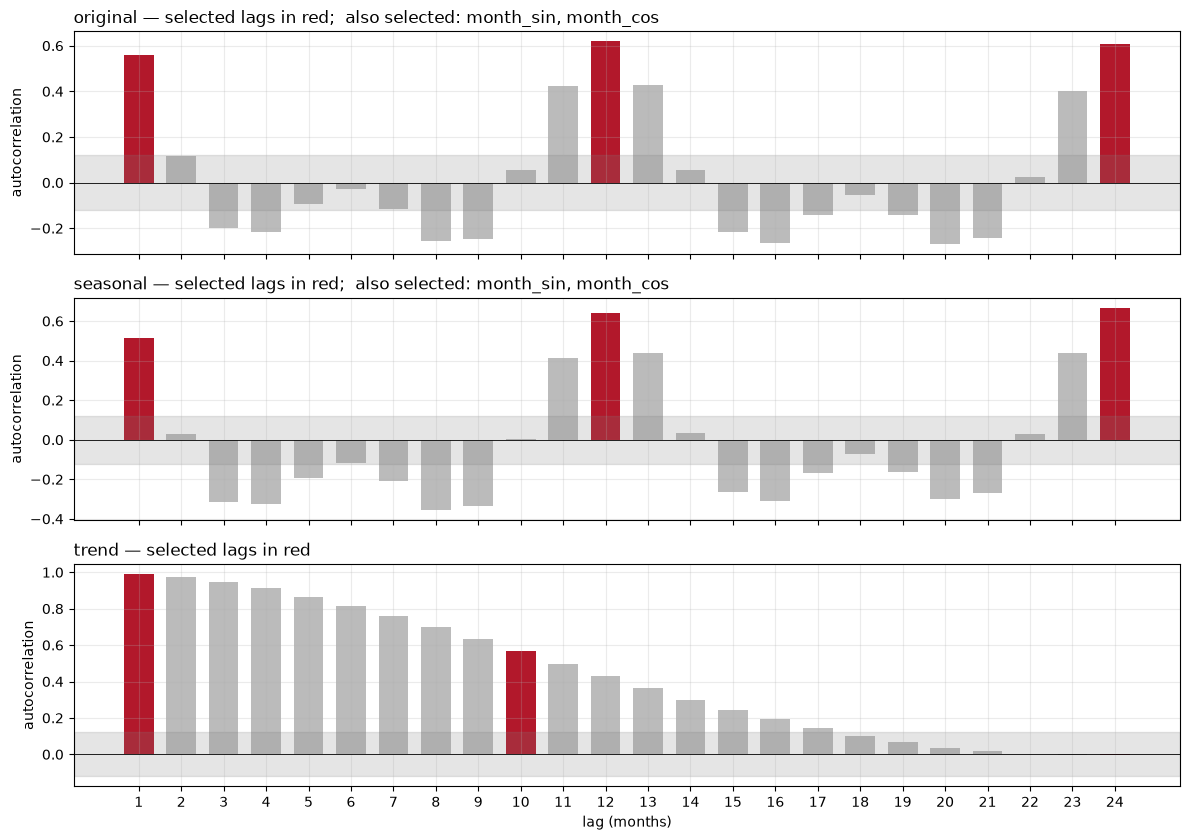

In [3]:
def acf(s, nlags):
    s = s.dropna() - s.dropna().mean()
    v = s.to_numpy()
    return np.array([(v[k:] * v[:-k]).sum() / (v * v).sum() for k in range(1, nlags + 1)])


fig, axes = plt.subplots(3, 1, figsize=(12, 8.5), sharex=True)
lags = np.arange(1, MAX_OWN_LAG + 1)
for ax, (branch, suf) in zip(axes, BRANCHES.items()):
    y = train[f"NDVI{suf}"]
    a = acf(y, MAX_OWN_LAG)
    chosen = [int(c.split("_lag")[1]) for c in own[branch] if "_lag" in c]
    colors = ["#b2182b" if k in chosen else "#bbbbbb" for k in lags]
    ax.bar(lags, a, color=colors, width=0.7)
    ax.axhline(0, color="black", lw=0.6)
    ci = 1.96 / np.sqrt(y.notna().sum())
    ax.axhspan(-ci, ci, color="grey", alpha=0.2)
    other = [c.replace(f"NDVI{suf}_", "") for c in own[branch] if "_lag" not in c]
    ax.set_title(f"{branch} — selected lags in red"
                 + (f";  also selected: {', '.join(other)}" if other else ""), loc="left")
    ax.set_ylabel("autocorrelation")
    ax.grid(alpha=0.25)
axes[-1].set_xlabel("lag (months)")
axes[-1].set_xticks(lags)
fig.tight_layout()
fig.savefig("../figures/03_own_history.png", dpi=150, bbox_inches="tight")
plt.show()

## Drought memory

The forest is green all year. Its NDVI is lowest in late winter and highest in
autumn, so two annual summaries over the training years are used:

- **winter low** (January–March minimum) — the seasonal low, when cold and short days
  limit the canopy, and when a deciduous component would be leafless
- **summer floor** (July–September minimum) — the canopy at the end of the dry season

Each is correlated with SPEI at the end of the wet season (May), first across
accumulation lengths from 3 months to 4 years, then for SPEI-12 of the same and of
earlier years. With about 20 years, only |r| above roughly 0.43 is significant, so
moderate effects cannot be excluded.

In [4]:
years = range(2001, TRAIN_END.year + 1)
low = pd.Series({y: d.loc[f"{y}-01-01":f"{y}-03-01", "NDVI"].min() for y in years})
floor = pd.Series({y: d.loc[f"{y}-07-01":f"{y}-09-01", "NDVI"].min() for y in years})


def at_may(y, col):
    t = pd.Timestamp(f"{y}-05-01")
    return d.at[t, col] if t in d.index else np.nan


def corr_table(columns):
    out = {}
    for label, series in [("winter low", low), ("summer floor", floor)]:
        out[label] = {name: series.corr(pd.Series({y: f(y) for y in years}))
                      for name, f in columns.items()}
    return pd.DataFrame(out).T


scales = ["SPEI_3", "SPEI_6", "SPEI_12", "SPEI_24", "SPEI_48"]
print(f"n = {len(years)} years; |r| > {1.96 / np.sqrt(len(years)):.2f} is significant at 5%\n")
print("SPEI-k in May of the same year")
print(corr_table({s: (lambda y, s=s: at_may(y, s)) for s in scales}).round(2).to_string())

print("\nSPEI-12 in May of the same and earlier years")
memory = {("year y" if k == 0 else f"y-{k}"): (lambda y, k=k: at_may(y - k, "SPEI_12"))
          for k in range(4)}
print(corr_table(memory).round(2).to_string())

n = 21 years; |r| > 0.43 is significant at 5%

SPEI-k in May of the same year
              SPEI_3  SPEI_6  SPEI_12  SPEI_24  SPEI_48
winter low      0.07   -0.49    -0.53    -0.34    -0.61
summer floor    0.23    0.19     0.17     0.16    -0.11

SPEI-12 in May of the same and earlier years
              year y   y-1   y-2   y-3
winter low     -0.53  0.05 -0.58 -0.03
summer floor    0.17  0.05 -0.43 -0.02


## Stage 2 — lagged climate

Each climate variable is lagged 1 to 12 months and correlated with what stage 1
leaves unexplained. The bound uses the effective sample size of Bretherton et al.
(1999) and a Bonferroni correction over the twelve lags. The expected sign (hotter
→ less green, wetter → greener) is recorded but not enforced: it holds where water
limits growth and not where cold does, and one rule has to serve both sites.

Where several SPEI lags pass, only the strongest is kept. The scales overlap
(SPEI-12 contains SPEI-6), so several passing lags are one signal counted several
times, which would let a linear model overfit and split the importance of one
signal across copies.

In [5]:
Z = norm.ppf(1 - 0.05 / (2 * MAX_CLIMATE_LAG))    # two-sided 5%, Bonferroni over lags


def stage1_residual(df, y, cols, name):
    C = own_history(df, y, name)[cols]
    D = pd.concat([y.rename("y"), C], axis=1).dropna()
    fit = LinearRegression().fit(D[cols], D["y"])
    return pd.Series(D["y"].to_numpy() - fit.predict(D[cols]), index=D.index)


def effective_n(n, r1a, r1b):
    """Bretherton et al. (1999), effective sample size for two autocorrelated series."""
    return n * (1 - r1a * r1b) / (1 + r1a * r1b)


def climate_evidence(train_df, own_sel):
    rows = []
    for branch, suf in BRANCHES.items():
        y = train_df[f"NDVI{suf}"]
        res = stage1_residual(train_df, y, own_sel[branch], f"NDVI{suf}")
        for var, sign in CLIMATE.items():
            x = train_df[f"{var}{suf}"]
            bound = Z / np.sqrt(effective_n(len(res), res.autocorr(1), x.autocorr(1)))
            for lag in range(1, MAX_CLIMATE_LAG + 1):
                r = res.corr(x.shift(lag).reindex(res.index))
                rows.append(dict(branch=branch, variable=var, lag=lag, r=r,
                                 bound=bound, expected=sign))
    ev = pd.DataFrame(rows)
    best = ev.loc[ev.groupby(["branch", "variable"])["r"]
                    .apply(lambda s: s.abs().idxmax())].reset_index(drop=True)
    significant = best["r"].abs() > best["bound"]
    best["sign"] = np.where(np.sign(best["r"]) == best["expected"], "as expected", "opposite")
    best["decision"] = np.where(significant, "selected", "not significant")

    # At most one drought predictor per branch. SPEI scales and lags overlap, so
    # several passing lags are one signal counted several times; the strongest,
    # by |r| / bound, is kept.
    passed = best["variable"].str.startswith("SPEI") & (best["decision"] == "selected")
    strength = best["r"].abs() / best["bound"]
    keep = strength[passed].groupby(best.loc[passed, "branch"]).idxmax()
    best.loc[passed & ~best.index.isin(keep), "decision"] = "redundant"
    return ev, best


ev, best = climate_evidence(train, own)
print(f"Bonferroni z = {Z:.2f}\n")
print(best.assign(r=best.r.round(3), bound=best.bound.round(3))
          .drop(columns="expected").to_string(index=False))

Bonferroni z = 2.87

  branch variable  lag      r  bound        sign        decision
original      LST    8  0.054  0.208    opposite not significant
original   SPEI_1    7  0.155  0.188 as expected not significant
original  SPEI_12    3  0.083  0.211 as expected not significant
original  SPEI_24   12 -0.165  0.212    opposite not significant
original   SPEI_3   11  0.153  0.202 as expected not significant
original  SPEI_48    1 -0.114  0.213    opposite not significant
original   SPEI_6    1 -0.077  0.208    opposite not significant
seasonal      LST    3  0.058  0.197    opposite not significant
seasonal   SPEI_1    7  0.145  0.186 as expected not significant
seasonal  SPEI_12    3  0.134  0.197 as expected not significant
seasonal  SPEI_24    6  0.222  0.194 as expected        selected
seasonal   SPEI_3   11  0.165  0.193 as expected not significant
seasonal  SPEI_48    7  0.128  0.196 as expected not significant
seasonal   SPEI_6    1 -0.172  0.195    opposite not significant
   t

### Correlation with the stage-1 residual, scaled by its bound

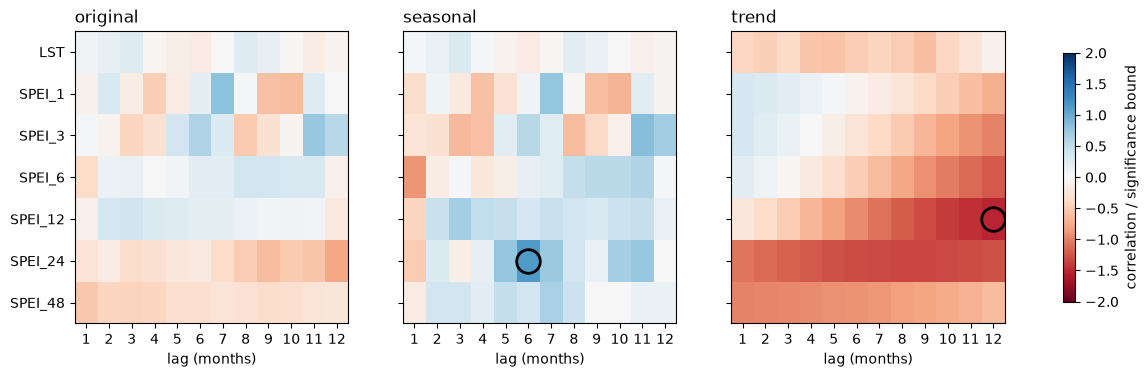

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, branch in zip(axes, BRANCHES):
    sub = ev[ev.branch == branch]
    grid = (sub.assign(z=sub.r / sub.bound)
               .pivot(index="variable", columns="lag", values="z")
               .loc[list(CLIMATE)])
    im = ax.imshow(grid, cmap="RdBu", vmin=-2, vmax=2, aspect="auto")
    ax.set_xticks(range(MAX_CLIMATE_LAG), range(1, MAX_CLIMATE_LAG + 1))
    ax.set_yticks(range(len(CLIMATE)), list(CLIMATE))
    for i, var in enumerate(CLIMATE):
        row = best[(best.branch == branch) & (best.variable == var)].iloc[0]
        if row.decision == "selected":
            ax.plot(row.lag - 1, i, "o", ms=17, mfc="none", mec="black", mew=2)
    ax.set_title(branch, loc="left")
    ax.set_xlabel("lag (months)")
fig.colorbar(im, ax=axes, shrink=0.85, label="correlation / significance bound")
fig.savefig("../figures/03_climate_evidence.png", dpi=150, bbox_inches="tight")
plt.show()

## Stage 3 — probes and family representatives

Random probe after Stoppiglia et al. (2003). LST lag 1 is kept on every branch even
when the linear screen rejects it: the screen tests for a straight-line relationship,
and whether a nonlinear model still uses the variable is part of the question.

Every branch keeps one drought feature: where no SPEI lag passed stage 2, the lag
with the strongest correlation relative to its bound is kept as the family's
representative.

In [7]:
NOISE = pd.Series(np.random.default_rng(0).standard_normal(len(d)),
                  index=d.index, name="noise_probe")

climate = {}
for branch, suf in BRANCHES.items():
    chosen = best[(best.branch == branch) & (best.decision == "selected")]
    climate[branch] = [f"{r.variable}{suf}_lag{r.lag}" for r in chosen.itertuples()]

controls = {branch: [f"LST{suf}_lag1"] for branch, suf in BRANCHES.items()
            if f"LST{suf}_lag1" not in climate[branch]}

representatives, rep_evidence = {}, {}
for branch, suf in BRANCHES.items():
    if not any(f.startswith("SPEI") for f in climate[branch]):
        spei = ev[(ev.branch == branch) & ev.variable.str.startswith("SPEI")]
        top = spei.loc[(spei.r.abs() / spei.bound).idxmax()]
        representatives[branch] = [f"{top.variable}{suf}_lag{top.lag}"]
        rep_evidence[branch] = (top.r, top.bound)

for branch in BRANCHES:
    print(f"{branch:9s} climate {climate[branch]}  representative {representatives.get(branch, [])}  "
          f"control {controls.get(branch, [])}  + noise_probe")

original  climate []  representative ['SPEI_1_lag7']  control ['LST_lag1']  + noise_probe
seasonal  climate ['SPEI_24_S_lag6']  representative []  control ['LST_S_lag1']  + noise_probe
trend     climate ['SPEI_12_T_lag12']  representative []  control ['LST_T_lag1']  + noise_probe


## Stability

Selection rerun on data up to December 2013.

In [8]:
early = d[d.index <= pd.Timestamp("2013-12-01")]
own_early = select_own(early)
_, best_early = climate_evidence(early, own_early)


def final_set(own_sel, best_sel, branch):
    suf = BRANCHES[branch]
    clim = best_sel[(best_sel.branch == branch) & (best_sel.decision == "selected")]
    return set(own_sel[branch]) | {f"{r.variable}{suf}_lag{r.lag}" for r in clim.itertuples()}


print(f"{'branch':9s} {'to 2021':>8s} {'to 2013':>8s} {'shared':>7s} {'Jaccard':>8s}")
for branch in BRANCHES:
    a = final_set(own, best, branch)
    b = final_set(own_early, best_early, branch)
    print(f"{branch:9s} {len(a):8d} {len(b):8d} {len(a & b):7d} {len(a & b) / len(a | b):8.2f}")
    if a != b:
        print(f"    only to 2021: {sorted(a - b)}")
        print(f"    only to 2013: {sorted(b - a)}")

branch     to 2021  to 2013  shared  Jaccard
original         5        5       5     1.00
seasonal         6       10       5     0.45
    only to 2021: ['SPEI_24_S_lag6']
    only to 2013: ['NDVI_S_lag23', 'NDVI_S_lag3', 'NDVI_S_lag8', 'NDVI_S_roll12', 'SPEI_12_S_lag1']
trend            4        4       4     1.00


## Feature tables and registry

Features are saved unscaled; scaling happens per training window in notebook 04.
The registry records every candidate, its decision and the reason.

In [9]:
def build(branch):
    suf = BRANCHES[branch]
    y = d[f"NDVI{suf}"]
    X = own_history(d, y, f"NDVI{suf}")[own[branch]].copy()
    for feat in climate[branch] + representatives.get(branch, []) + controls.get(branch, []):
        base, lag = feat.rsplit("_lag", 1)
        X[feat] = d[base].shift(int(lag))
    X["noise_probe"] = NOISE
    out = X.assign(target=y).dropna()
    out["split"] = np.where(out.index <= TRAIN_END, "train", "test")
    return out


tables = {}
for branch in BRANCHES:
    tables[branch] = build(branch)
    tables[branch].to_csv(f"../data/processed/features_{branch}.csv")
    t = tables[branch]
    print(f"{branch:9s} {t.shape[1] - 2:2d} features | rows {len(t)} "
          f"({t.index.min():%Y-%m} -> {t.index.max():%Y-%m}) | "
          f"{t.split.value_counts().to_dict()}")

original   8 features | rows 274 (2002-03 -> 2024-12) | {'train': 238, 'test': 36}
seasonal   8 features | rows 274 (2002-03 -> 2024-12) | {'train': 238, 'test': 36}
trend      6 features | rows 274 (2002-03 -> 2024-12) | {'train': 238, 'test': 36}


In [10]:
rows = []
for branch, suf in BRANCHES.items():
    y = train[f"NDVI{suf}"]
    for cand in own_history(train, y, f"NDVI{suf}").columns:
        family = "calendar" if cand.startswith("month") else "own history"
        if cand in FIXED[branch]:
            decision, reason = "given to every model", "the season, which tree models cannot rebuild from lags"
        else:
            decision = "selected" if cand in own[branch] else "not selected"
            reason = "lasso, time-series CV, one-standard-error rule"
        rows.append(dict(branch=branch, feature=cand, family=family, stage=1,
                         decision=decision, reason=reason))
    rows.append(dict(branch=branch, feature="time_index", family="time", stage=1,
                     decision="excluded a priori",
                     reason="not extrapolable by tree models; would differ by model class"))
    for r in best[best.branch == branch].itertuples():
        rows.append(dict(branch=branch, feature=f"{r.variable}{suf}_lag{r.lag}",
                         family="LST" if r.variable == "LST" else "drought",
                         stage=2, decision=r.decision,
                         reason=f"best of lags 1-12: r={r.r:+.3f}, bound {r.bound:.3f}, sign {r.sign}"
                                + ("; a stronger drought lag was kept" if r.decision == "redundant" else "")))
    for feat in representatives.get(branch, []):
        rows.append(dict(branch=branch, feature=feat, family="drought",
                         stage=3, decision="family representative",
                         reason=f"no SPEI lag passed; strongest lag kept "
                                f"(r={rep_evidence[branch][0]:+.3f}, bound {rep_evidence[branch][1]:.3f})"))
    for feat in controls.get(branch, []):
        rows.append(dict(branch=branch, feature=feat, family="LST", stage=3,
                         decision="rejected by the linear screen, kept",
                         reason="no linear incremental evidence in stage 2; kept to see "
                                "how each model uses it"))
    rows.append(dict(branch=branch, feature="noise_probe", family="probe", stage=3,
                     decision="random probe",
                     reason="Gaussian noise, seed 0; true importance zero"))

registry = pd.DataFrame(rows)
registry.to_csv("../results/feature_registry.csv", index=False)

used = registry[registry.decision.isin(["selected", "given to every model", "family representative",
                                         "rejected by the linear screen, kept", "random probe"])]
print(f"registry: {len(registry)} candidates recorded, {len(used)} used\n")
print(used.groupby(["branch", "family"]).size().unstack(fill_value=0).to_string())

registry: 118 candidates recorded, 22 used

family    LST  calendar  drought  own history  probe
branch                                              
original    1         2        1            3      1
seasonal    1         2        1            3      1
trend       1         0        1            3      1
